# experiment_1 — YOLO26n 사전학습 가중치 + 합성 데이터 (train / val / test)

| 항목 | 내용 |
| --- | --- |
| 목적 | 공식 `yolo26n.pt`(COCO 사전학습)에서 시작해 광각 합성 데이터로 학습하고, **따로 떼어 둔 test 세트로 최종 평가** |
| 데이터 | `yolo/datasets/turtle_ninja` 의 합성 500장(wide_001)을 seed 고정으로 train / val / test 로 다시 나눔 |
| 기록 | 이 노트북의 셀 출력 + `yolo/train/results/<RUN_ID>/`에 로그·설정·지표·가중치·결과 이미지 (git 제외) |
| 모델 선택 | epoch마다 val **mAP50**이 최고일 때 가중치를 `weights/best_map50.pt`로 저장 → 평가·추론은 모두 이 파일 사용 |
| 실물 테스트 | `yolo/datasets/real_wide_test/`의 실제 광각 사진을 **합성 test와 따로** 평가·시각화 (mAP50, 클래스별, 정답 vs 예측 이미지) |

**실행 방법 (둘 중 하나)**

1. VS Code / Jupyter에서 커널을 `.venv-yolo`로 고르고 위에서부터 차례로 실행 → 저장(Ctrl+S)하면 출력이 노트북에 남아요.
2. 터미널에서 한 번에 실행하고 출력까지 노트북에 저장:
   ```bash
   cd ~/바탕화면/git/Project2_Turtle_Ninja/yolo/train
   ~/pa-course/.venv-yolo/bin/jupyter nbconvert --to notebook --execute --inplace \
       --ExecutePreprocessor.timeout=-1 experiment_1.ipynb
   ```

처음 한 번만 커널 준비:
```bash
~/pa-course/.venv-yolo/bin/pip install ipykernel nbconvert
~/pa-course/.venv-yolo/bin/python -m ipykernel install --user --name venv-yolo --display-name "Python (.venv-yolo)"
```

**실물 광각 테스트 사진 넣는 법** (없으면 그 부분만 건너뜀)
```
yolo/datasets/real_wide_test/
├── images/   real_0001.jpg ...   ← Arducam 원본(보정 전) 1280x720, 로봇과 같은 방향으로
└── labels/   real_0001.txt ...   ← YOLO 형식 "cls cx cy w h" (0~1), 클래스 번호 0 qr · 1 puck_cyl(원기둥) · 2 puck_box(직육면체) · 3 signal_tower — 누운 퍽도 모양대로
```
라벨이 없는 사진은 예측 결과만 보여 주고 mAP 계산에서는 빠져요. 물체가 하나도 없는 사진은 **빈 .txt**를 두면 오탐 확인용 배경 사진으로 계산돼요.

**셀 순서**: 0 설정 → 1 로그 시작 → 2 환경 기록 → 3 클래스 정의 확인 → 4 train/val/test 나누기 → 4-R 실물 테스트셋 확인 → 5 데이터 통계·샘플 → 6 사전학습 가중치 받기 → 7 학습 (mAP50 best 저장) → 8 학습 곡선 → 9 합성 val·test 평가 → 9-R 실물 테스트 평가 → 10 합성 test 예측 → 10-R 실물 정답 vs 예측 → 11 요약

## 0. 설정 — 실험마다 여기만 바꾸기

In [5]:
from pathlib import Path
from datetime import datetime

EXP_NAME = "experiment_1"
RUN_ID = f"{EXP_NAME}_{datetime.now():%Y%m%d_%H%M%S}"   # 다시 돌려도 이전 기록을 덮어쓰지 않음

HOME = Path.home()
REPO = HOME / "바탕화면/git/Project2_Turtle_Ninja"
SRC_DATASET = REPO / "yolo/datasets/turtle_ninja_shape"      # convert_to_yolo.py --classes shape 결과 (모양 구분 6클래스)
SRC_SPLITS = ["train"]                                         # 여기 있는 사진을 전부 모아서 다시 나눔
SPLIT_SEED = 0
SPLIT_RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
SPLIT_DATASET = REPO / f"yolo/datasets/turtle_ninja_split_s{SPLIT_SEED}_shape4"   # git 제외 폴더. 4클래스(모양 구분, 누운 퍽 포함)

WEIGHTS_DIR = REPO / "yolo/models"                             # *.pt 는 git 제외
PRETRAINED = WEIGHTS_DIR / "yolo26n.pt"

REAL_TEST_DIR = REPO / "yolo/datasets/real_wide_test"         # 실제 광각 사진 (images/, labels/)
CONF = 0.5                                                     # 예측 표시 기준 = planning 기준 (0.5 미만은 버림)

PROJECT = REPO / "yolo/train/results"                          # 이 노트북 폴더 안. 폴더 전체가 git 제외됨
EXP_DIR = PROJECT / RUN_ID
BEST_MAP50 = EXP_DIR / "weights" / "best_map50.pt"             # val mAP50 최고 epoch 가중치

TRAIN_CFG = dict(
    epochs=50,
    patience=20,          # val 성능이 20 epoch 동안 안 좋아지면 멈춤
    imgsz=1280,           # 광각 원본 1280x720
    batch=8,
    device=0,
    workers=8,
    seed=0,
    deterministic=True,
    optimizer="auto",
    close_mosaic=10,      # 마지막 10 epoch는 mosaic 끔
    hsv_h=0.015,          # 기본값. 가이드 권장 0.3은 experiment_2에서 비교
    pretrained=True,
    plots=True,
    save=True,
    verbose=True,
)
print("RUN_ID     :", RUN_ID)
print("EXP_DIR    :", EXP_DIR)
print("SRC        :", SRC_DATASET, SRC_SPLITS)
print("SPLIT      :", SPLIT_DATASET, SPLIT_RATIO, "seed", SPLIT_SEED)
print("PRETRAINED :", PRETRAINED)
print("REAL TEST  :", REAL_TEST_DIR)
print("CONF       :", CONF)

RUN_ID     : experiment_1_20261023_110611
EXP_DIR    : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611
SRC        : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_shape ['train']
SPLIT      : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4 {'train': 0.8, 'val': 0.1, 'test': 0.1} seed 0
PRETRAINED : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
REAL TEST  : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/real_wide_test
CONF       : 0.5


## 1. 로그 시작 — 이 셀 이후의 모든 출력이 `run.log`에도 저장돼요

In [6]:
import sys, json, logging

PROJECT.mkdir(parents=True, exist_ok=True)
gi = PROJECT / ".gitignore"
if not gi.exists():
    gi.write_text("# 실험 결과(가중치·이미지·로그)는 커밋하지 않음\n*\n", encoding="utf-8")
EXP_DIR.mkdir(parents=True, exist_ok=False)
LOG_PATH = EXP_DIR / "run.log"

class Tee:
    """화면 출력과 run.log에 동시에 쓰기 (노트북 출력은 그대로 남음)."""
    def __init__(self, stream, path):
        self.stream, self.file = stream, open(path, "a", encoding="utf-8", buffering=1)
    def write(self, s):
        self.stream.write(s)
        self.file.write(s)
        return len(s)
    def flush(self):
        self.stream.flush(); self.file.flush()
    def __getattr__(self, name):
        return getattr(self.stream, name)

if not isinstance(sys.stdout, Tee):
    sys.stdout = Tee(sys.stdout, LOG_PATH)
    sys.stderr = Tee(sys.stderr, LOG_PATH)

def save_json(name, obj):
    p = EXP_DIR / name
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print("saved", p)

save_json("config.json", dict(RUN_ID=RUN_ID, SRC_DATASET=SRC_DATASET, SRC_SPLITS=SRC_SPLITS,
                              SPLIT_SEED=SPLIT_SEED, SPLIT_RATIO=SPLIT_RATIO,
                              SPLIT_DATASET=SPLIT_DATASET, PRETRAINED=PRETRAINED, TRAIN_CFG=TRAIN_CFG,
                              REAL_TEST_DIR=REAL_TEST_DIR, CONF=CONF, model_selection="max val mAP50"))
print(f"[{datetime.now():%F %T}] 로그 시작 → {LOG_PATH}")

saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/config.json
[2026-10-23 11:06:11] 로그 시작 → /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/run.log


## 2. 환경 기록 — 버전·GPU·git 상태

In [7]:
import platform, subprocess
import torch, ultralytics

def git(*args):
    try:
        return subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True).stdout.strip()
    except Exception as e:
        return f"error: {e}"

env = dict(
    time=datetime.now().isoformat(timespec="seconds"),
    python=sys.version.split()[0],
    platform=platform.platform(),
    torch=torch.__version__,
    cuda_available=torch.cuda.is_available(),
    cuda=torch.version.cuda,
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    ultralytics=ultralytics.__version__,
    git_branch=git("rev-parse", "--abbrev-ref", "HEAD"),
    git_commit=git("rev-parse", "--short", "HEAD"),
    git_dirty_files=len([l for l in git("status", "--porcelain").splitlines() if l.strip()]),
)
for k, v in env.items():
    print(f"{k:16s} {v}")
save_json("env.json", env)
assert env["cuda_available"], "GPU가 안 잡혀요. 커널이 .venv-yolo인지 확인하세요."

time             2026-10-23T11:06:11
python           3.12.3
platform         Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch            2.11.0+cu128
cuda_available   True
cuda             12.8
gpu              NVIDIA GeForce RTX 5060 Laptop GPU
ultralytics      8.4.183
git_branch       feat/camera_calib
git_commit       5d48516
git_dirty_files  4
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/env.json


## 3. 클래스 정의 — 학습 전에 눈으로 확인

**4클래스 (퍽 모양 구분)**: 원기둥 퍽 `puck_cyl`과 직육면체 퍽 `puck_box`를 나눠요. 누운 퍽은 따로 두지 않고 **모양 클래스에 포함**해요. planning `shape` 필드(`cylinder` / `box`)와 1:1로 맞아요.

원본 데이터는 `convert_to_yolo.py --classes shape`로 변환한 6클래스(`qr, puck_cyl, puck_box, puck_cyl_fallen, puck_box_fallen, signal_tower`)예요. 4번 셀에서 split 폴더를 만들 때 라벨 번호를 아래 `SRC_TO_NEW` 표대로 바꿔 써요. 원본 파일은 건드리지 않아요. 원본 `data.yaml`의 이름이 예상과 다르면 이 셀에서 멈춰요.

원본이 없으면 먼저 터미널에서 (feat/camera_calib 브랜치, 레포 루트):
```bash
python3 yolo/dataset_gen/convert_to_yolo.py yolo/datasets/sim_raw/wide_001 yolo/datasets/turtle_ninja_shape \
    --split train --prefix wide_001 --classes shape
```

In [8]:
import yaml

CLASSES = [
    # id, 이름,          무엇인지,                                    sim 원본 라벨 (convert_to_yolo.py)
    (0, "qr",           "벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)", "qr"),
    (1, "puck_cyl",     "원기둥 퍽 Ø30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=cylinder",
                        "puck_cyl, puck_cyl_fallen"),
    (2, "puck_box",     "직육면체 퍽 30x30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=box",
                        "puck_box, puck_box_fallen"),
    (3, "signal_tower", "신호등 기둥 전체 (점등 색은 후처리로 판별)",                 "signal_tower"),
]
NOT_LABELED = {"wall_joint": "파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습"}

NAMES = {i: n for i, n, _, _ in CLASSES}
print(f"{'id':>2}  {'name':14s} {'sim 라벨':34s} 설명")
print("-" * 110)
for i, n, desc, src in CLASSES:
    print(f"{i:>2}  {n:14s} {src:34s} {desc}")
for n, desc in NOT_LABELED.items():
    print(f" -  {n:14s} {'(라벨 없음)':34s} {desc}")

src_yaml = yaml.safe_load((SRC_DATASET / "data.yaml").read_text(encoding="utf-8"))
src_names = {int(k): v for k, v in src_yaml["names"].items()} if isinstance(src_yaml["names"], dict) \
    else dict(enumerate(src_yaml["names"]))
print("\n원본 data.yaml names:", src_names)
EXPECTED_SRC = {0: "qr", 1: "puck_cyl", 2: "puck_box", 3: "puck_cyl_fallen", 4: "puck_box_fallen", 5: "signal_tower"}
assert src_names == EXPECTED_SRC, f"원본 data.yaml 클래스가 예상과 달라요: {src_names}"
MERGE = {"qr": "qr", "puck_cyl": "puck_cyl", "puck_box": "puck_box",                       # 원본 이름 → 새 이름
         "puck_cyl_fallen": "puck_cyl", "puck_box_fallen": "puck_box", "signal_tower": "signal_tower"}
NEW_ID = {n: i for i, n in NAMES.items()}
SRC_TO_NEW = {i: NEW_ID[MERGE[n]] for i, n in src_names.items()}
print("라벨 번호 변환 SRC_TO_NEW:", ", ".join(f"{i}({src_names[i]}) → {j}({NAMES[j]})" for i, j in SRC_TO_NEW.items()))
print("✔ 클래스 정의 확인")
save_json("classes.json", dict(classes=[dict(id=i, name=n, description=d, sim_labels=s) for i, n, d, s in CLASSES],
                               not_labeled=NOT_LABELED, source_names=src_names, src_to_new=SRC_TO_NEW))

id  name           sim 라벨                             설명
--------------------------------------------------------------------------------------------------------------
 0  qr             qr                                 벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)
 1  puck_cyl       puck_cyl, puck_cyl_fallen          원기둥 퍽 Ø30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=cylinder
 2  puck_box       puck_box, puck_box_fallen          직육면체 퍽 30x30x60mm. 서 있든 누워 있든 (색은 후처리 HSV) → planning shape=box
 3  signal_tower   signal_tower                       신호등 기둥 전체 (점등 색은 후처리로 판별)
 -  wall_joint     (라벨 없음)                            파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습

원본 data.yaml names: {0: 'qr', 1: 'puck_cyl', 2: 'puck_box', 3: 'puck_cyl_fallen', 4: 'puck_box_fallen', 5: 'signal_tower'}
라벨 번호 변환 SRC_TO_NEW: 0(qr) → 0(qr), 1(puck_cyl) → 1(puck_cyl), 2(puck_box) → 2(puck_box), 3(puck_cyl_fallen) → 1(puck_cyl), 4(puck_box_fallen) → 2(puck_box), 5(signal_tower) → 3(signal_tower)
✔ 클래스 정의 확

## 4. train / val / test 나누기

- 원본 폴더의 사진을 모두 모아 `SPLIT_SEED`로 섞고 8:1:1로 나눠요. 같은 seed면 항상 같은 결과예요.
- 사진은 **심볼릭 링크**, 라벨은 4클래스 번호로 **바꿔서 새로 써요** → 새 폴더 `turtle_ninja_split_s0_shape4`.
- 폴더가 이미 있으면 새로 만들지 않고, 저장된 목록(`split_manifest.csv`)과 같은지 확인만 해요.
- **test는 학습·조기 종료에 전혀 쓰지 않고** 마지막 9번 셀에서 한 번만 평가해요.

In [9]:
import csv, random, os

def collect_pairs():
    pairs = []
    for s in SRC_SPLITS:
        for img in sorted((SRC_DATASET / "images" / s).glob("*.png")):
            lbl = SRC_DATASET / "labels" / s / (img.stem + ".txt")
            assert lbl.exists(), f"라벨 없음: {lbl}"
            pairs.append((img, lbl))
    return pairs

pairs = collect_pairs()
print("원본 사진 수:", len(pairs), {s: len(list((SRC_DATASET / 'images' / s).glob('*.png'))) for s in SRC_SPLITS})

order = list(range(len(pairs)))
random.Random(SPLIT_SEED).shuffle(order)
n = len(order)
n_train = round(n * SPLIT_RATIO["train"]); n_val = round(n * SPLIT_RATIO["val"])
assign = {}
for k, idx in enumerate(order):
    assign[idx] = "train" if k < n_train else "val" if k < n_train + n_val else "test"

manifest = [(assign[i], pairs[i][0].name, str(pairs[i][0])) for i in range(n)]
manifest.sort()
manifest_path = SPLIT_DATASET / "split_manifest.csv"

if SPLIT_DATASET.exists():
    with open(manifest_path, encoding="utf-8") as f:
        old = [tuple(r) for r in csv.reader(f)][1:]
    assert old == [tuple(m) for m in manifest], "기존 split 폴더와 목록이 달라요. SPLIT_SEED나 원본이 바뀌었는지 확인하세요."
    print("기존 split 폴더 재사용:", SPLIT_DATASET)
else:
    for i, (img, lbl) in enumerate(pairs):
        s = assign[i]
        (SPLIT_DATASET / "images" / s).mkdir(parents=True, exist_ok=True)
        (SPLIT_DATASET / "labels" / s).mkdir(parents=True, exist_ok=True)
        os.symlink(img.resolve(), SPLIT_DATASET / "images" / s / img.name)
        out = []
        for l in lbl.read_text().splitlines():
            if l.strip():
                c, *rest = l.split()
                out.append(" ".join([str(SRC_TO_NEW[int(c)]), *rest]))
        (SPLIT_DATASET / "labels" / s / lbl.name).write_text("\n".join(out) + ("\n" if out else ""))
    with open(manifest_path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["split", "file", "source"]); w.writerows(manifest)
    print("새 split 폴더 생성:", SPLIT_DATASET)

DATA_YAML = SPLIT_DATASET / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(dict(path=str(SPLIT_DATASET), train="images/train", val="images/val",
                                         test="images/test", names=NAMES), allow_unicode=True, sort_keys=False),
                     encoding="utf-8")
print(DATA_YAML.read_text(encoding="utf-8"))

import shutil
shutil.copy2(manifest_path, EXP_DIR / "split_manifest.csv")
shutil.copy2(DATA_YAML, EXP_DIR / "data.yaml")
for s in ("train", "val", "test"):
    print(f"{s:5s}: {sum(1 for v in assign.values() if v == s)}장")

원본 사진 수: 500 {'train': 500}
기존 split 폴더 재사용: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4
path: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4
train: images/train
val: images/val
test: images/test
names:
  0: qr
  1: puck_cyl
  2: puck_box
  3: signal_tower

train: 400장
val  : 50장
test : 50장


## 4-R. 실물 광각 테스트셋 확인 — 합성 데이터와 완전히 별도

- 학습·검증에는 전혀 쓰지 않고 9-R·10-R에서만 써요.
- 라벨(`labels/*.txt`)이 있는 사진만 mAP에 들어가요. 빈 .txt = 물체 없음(배경) 사진.
- 해상도가 1280x720이 아니거나 라벨 클래스 번호가 범위를 벗어나면 경고해요.

In [10]:
from PIL import Image
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")
real_imgs = sorted(p for p in (REAL_TEST_DIR / "images").glob("*") if p.suffix.lower() in IMG_EXT) \
    if (REAL_TEST_DIR / "images").exists() else []
real_labeled, real_unlabeled = [], []
real_stats = dict(images=len(real_imgs), labeled=0, unlabeled=0, background=0, boxes=0,
                  per_class={NAMES[c]: 0 for c in NAMES}, bad_size=[], bad_class=[])
for p in real_imgs:
    lbl = REAL_TEST_DIR / "labels" / (p.stem + ".txt")
    with Image.open(p) as im:
        w, h = im.size
    if (w, h) != (1280, 720):
        real_stats["bad_size"].append(f"{p.name} {w}x{h}")
    if not lbl.exists():
        real_unlabeled.append(p); continue
    real_labeled.append(p)
    rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
    real_stats["background"] += not rows
    for r in rows:
        c = int(r[0])
        if c not in NAMES:
            real_stats["bad_class"].append(f"{lbl.name}: {c}"); continue
        real_stats["per_class"][NAMES[c]] += 1; real_stats["boxes"] += 1
real_stats["labeled"], real_stats["unlabeled"] = len(real_labeled), len(real_unlabeled)
HAS_REAL = len(real_imgs) > 0
HAS_REAL_LABELS = len(real_labeled) > 0

print(f"실물 사진 {real_stats['images']}장 | 라벨 있음 {real_stats['labeled']} (배경 {real_stats['background']}) "
      f"| 라벨 없음 {real_stats['unlabeled']} | 상자 {real_stats['boxes']}")
print("클래스별 상자:", real_stats["per_class"])
if real_stats["bad_size"]:  print("⚠ 1280x720 아님:", real_stats["bad_size"])
if real_stats["bad_class"]: print("⚠ 없는 클래스 번호:", real_stats["bad_class"])
if not HAS_REAL:
    print(f"⚠ 실물 사진이 없어요 → 9-R·10-R은 건너뜀 ({REAL_TEST_DIR / 'images'})")
elif not HAS_REAL_LABELS:
    print("⚠ 라벨이 하나도 없어요 → 9-R(mAP)은 건너뛰고 10-R에서 예측 결과만 보여줌")

# mAP 계산용: 라벨 있는 사진만 링크로 모은 별도 폴더 + data_real.yaml (합성 data.yaml과 분리)
REAL_EVAL_DIR = EXP_DIR / "real_test_set"
if HAS_REAL_LABELS:
    for kind in ("images", "labels"):
        (REAL_EVAL_DIR / kind / "test").mkdir(parents=True, exist_ok=True)
    for p in real_labeled:
        os.symlink(p.resolve(), REAL_EVAL_DIR / "images" / "test" / p.name)
        os.symlink((REAL_TEST_DIR / "labels" / (p.stem + ".txt")).resolve(), REAL_EVAL_DIR / "labels" / "test" / (p.stem + ".txt"))
    DATA_REAL_YAML = EXP_DIR / "data_real.yaml"
    DATA_REAL_YAML.write_text(yaml.safe_dump(dict(path=str(REAL_EVAL_DIR), train="images/test", val="images/test",
                                                  test="images/test", names=NAMES), allow_unicode=True, sort_keys=False),
                              encoding="utf-8")
    print(DATA_REAL_YAML.read_text(encoding="utf-8"))
save_json("real_test_stats.json", dict(real_stats, labeled_files=[p.name for p in real_labeled],
                                       unlabeled_files=[p.name for p in real_unlabeled]))

실물 사진 49장 | 라벨 있음 49 (배경 2) | 라벨 없음 0 | 상자 94
클래스별 상자: {'qr': 23, 'puck_cyl': 68, 'puck_box': 3, 'signal_tower': 0}
path: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/real_test_set
train: images/test
val: images/test
test: images/test
names:
  0: qr
  1: puck_cyl
  2: puck_box
  3: signal_tower

saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/real_test_stats.json


## 5. 데이터 통계와 라벨 샘플 — split마다 클래스 수가 고르게 들어갔는지 확인

split     사진    빈사진     상자            qr      puck_cyl      puck_box  signal_tower
train    400      5   1102             0           457           475           170
val       50      0    132             0            41            66            25
test      50      0    149             0            68            58            23
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/dataset_stats.json
⚠ train에 'qr' 상자가 0개 → 이 클래스는 train 지표가 안 나와요
⚠ val에 'qr' 상자가 0개 → 이 클래스는 val 지표가 안 나와요
⚠ test에 'qr' 상자가 0개 → 이 클래스는 test 지표가 안 나와요


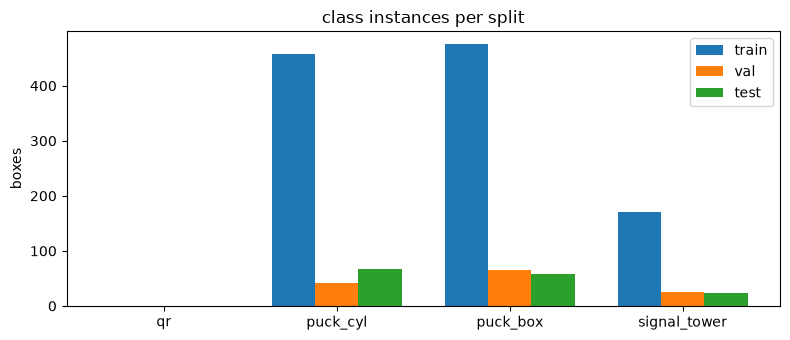

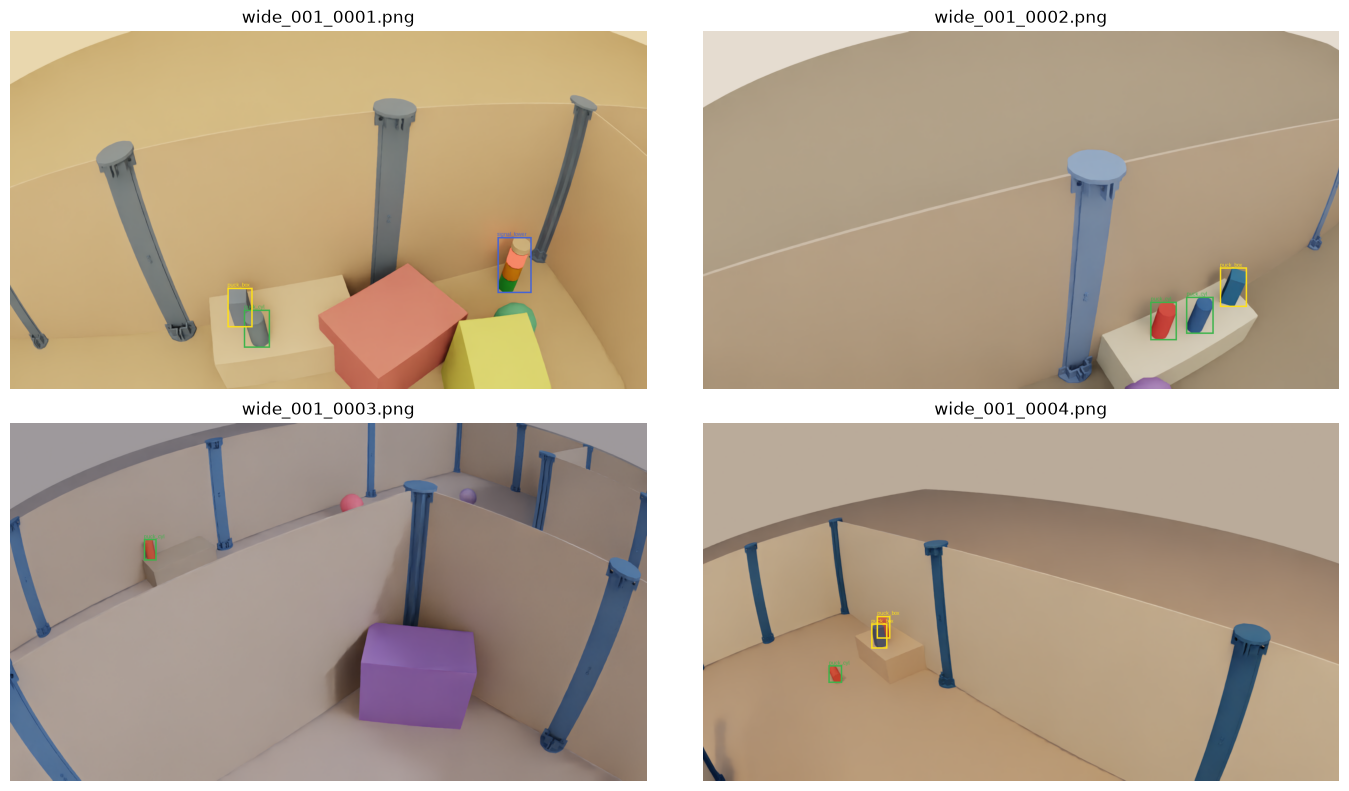

In [11]:
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

stats = {}
for s in ("train", "val", "test"):
    cnt, empty, n_img = Counter(), 0, 0
    for lbl in sorted((SPLIT_DATASET / "labels" / s).glob("*.txt")):
        rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
        n_img += 1
        empty += not rows
        cnt.update(int(r[0]) for r in rows)
    stats[s] = dict(images=n_img, empty_images=empty, boxes=sum(cnt.values()),
                    per_class={NAMES[c]: cnt.get(c, 0) for c in NAMES})

print(f"{'split':6s} {'사진':>5s} {'빈사진':>6s} {'상자':>6s}  " + "  ".join(f"{NAMES[c]:>12s}" for c in NAMES))
for s, st in stats.items():
    print(f"{s:6s} {st['images']:5d} {st['empty_images']:6d} {st['boxes']:6d}  "
          + "  ".join(f"{st['per_class'][NAMES[c]]:12d}" for c in NAMES))
save_json("dataset_stats.json", stats)
for s, st in stats.items():
    for c in NAMES:
        if st["per_class"][NAMES[c]] == 0:
            print(f"⚠ {s}에 '{NAMES[c]}' 상자가 0개 → 이 클래스는 {s} 지표가 안 나와요")

fig, ax = plt.subplots(figsize=(8, 3.5))
w = 0.25
for k, s in enumerate(stats):
    ax.bar([c + (k - 1) * w for c in NAMES], [stats[s]["per_class"][NAMES[c]] for c in NAMES], w, label=s)
ax.set_xticks(list(NAMES)); ax.set_xticklabels(list(NAMES.values())); ax.set_ylabel("boxes"); ax.legend()
ax.set_title("class instances per split"); fig.tight_layout()
fig.savefig(EXP_DIR / "class_counts.png", dpi=120); plt.show()

COLORS = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8"]
def draw(img_path, lbl_path):
    im = Image.open(img_path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for l in lbl_path.read_text().splitlines():
        if not l.strip(): continue
        c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
        x0, y0, x1, y1 = (cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H
        d.rectangle([x0, y0, x1, y1], outline=COLORS[c % 4], width=3)
        d.text((x0, max(0, y0 - 12)), NAMES[c], fill=COLORS[c % 4])
    return im

samples = sorted((SPLIT_DATASET / "images" / "train").glob("*.png"))[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, p in zip(axes.flat, samples):
    a.imshow(draw(p, SPLIT_DATASET / "labels" / "train" / (p.stem + ".txt"))); a.set_title(p.name); a.axis("off")
fig.tight_layout(); fig.savefig(EXP_DIR / "label_samples.png", dpi=80); plt.show()

## 6. 사전학습 가중치 받기 — `yolo26n.pt` (COCO 80클래스)

- Ultralytics 공식 배포 파일을 `yolo/models/yolo26n.pt`로 직접 내려받아요. 이미 있으면 다시 받지 않아요.
- 파일 크기와 SHA256을 기록해서 나중에 같은 가중치였는지 확인할 수 있게 해요.
- 학습을 시작하면 머리(head)는 우리 4클래스로 새로 만들고 나머지 층은 이 가중치를 이어받아요. 7번 셀 로그의 `Transferred N/M items` 줄이 그 증거예요.

In [12]:
import hashlib
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset

WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
if not PRETRAINED.exists():
    print("다운로드:", PRETRAINED.name)
    got = Path(attempt_download_asset(str(PRETRAINED)))
    assert got.resolve() == PRETRAINED.resolve() and PRETRAINED.exists(), f"다운로드 실패: {got}"
else:
    print("이미 있음:", PRETRAINED)

sha = hashlib.sha256(PRETRAINED.read_bytes()).hexdigest()
pre = YOLO(str(PRETRAINED))
n_params = sum(p.numel() for p in pre.model.parameters())
weights_info = dict(path=PRETRAINED, size_bytes=PRETRAINED.stat().st_size, sha256=sha,
                    task=pre.task, n_classes=len(pre.names), params=n_params)
for k, v in weights_info.items():
    print(f"{k:11s} {v}")
print("사전학습 클래스 예시:", list(pre.names.values())[:8], "...")
pre.info(detailed=False)
save_json("pretrained.json", weights_info)
del pre

이미 있음: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
path        /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
size_bytes  5544453
sha256      9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef
task        detect
n_classes   80
params      2572280
사전학습 클래스 예시: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck'] ...
YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs
saved /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/pretrained.json


## 7. 학습 — val mAP50 최고 epoch를 `best_map50.pt`로 저장

- Ultralytics 기본 `best.pt`는 mAP50-95 위주 점수(fitness)로 골라요. 이 실험은 **mAP50 기준**이라 epoch마다 val mAP50을 보고, 최고를 갱신하면 그 epoch 가중치를 `weights/best_map50.pt`로 복사해요.
- 이후 평가(9, 9-R)와 추론(10, 10-R)은 전부 `best_map50.pt`를 써요.
- 진행 로그는 이 셀 출력과 `run.log`, epoch별 수치는 `results.csv`.

In [13]:
import time

best_map50 = {"mAP50": -1.0, "epoch": None}

def save_best_map50(trainer):
    """epoch 끝(val + last.pt 저장 직후)마다 호출. val mAP50이 최고면 last.pt를 best_map50.pt로 복사."""
    m = trainer.metrics.get("metrics/mAP50(B)")
    if m is None or not Path(trainer.last).exists():
        return
    if float(m) > best_map50["mAP50"]:
        best_map50.update(mAP50=float(m), epoch=int(trainer.epoch) + 1)
        BEST_MAP50.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(trainer.last, BEST_MAP50)
        print(f"[best_map50] epoch {trainer.epoch + 1}: val mAP50 {float(m):.4f} → {BEST_MAP50.name} 저장")

model = YOLO(str(PRETRAINED))
model.add_callback("on_fit_epoch_end", save_best_map50)
t0 = time.time()
train_results = model.train(data=str(DATA_YAML), project=str(PROJECT), name=RUN_ID, exist_ok=True, **TRAIN_CFG)
train_min = (time.time() - t0) / 60
SAVE_DIR = Path(model.trainer.save_dir)
assert SAVE_DIR.resolve() == EXP_DIR.resolve(), f"결과 폴더가 다름: {SAVE_DIR}"
assert BEST_MAP50.exists(), "best_map50.pt가 저장되지 않았어요. 위 로그를 확인하세요."
print(f"\n학습 시간 {train_min:.1f}분 | 결과 폴더 {SAVE_DIR}")
print(f"선택한 가중치: {BEST_MAP50}  (epoch {best_map50['epoch']}, val mAP50 {best_map50['mAP50']:.4f})")

transfer = [l.strip() for l in LOG_PATH.read_text(encoding="utf-8", errors="ignore").splitlines() if "Transferred" in l]
print("사전학습 가중치 이어받기:", transfer[-1] if transfer else "⚠ 'Transferred' 줄을 못 찾음 — 위 로그 확인")
save_json("train_info.json", dict(train_minutes=round(train_min, 2), save_dir=SAVE_DIR, best_map50=BEST_MAP50,
                                  best_epoch=best_map50["epoch"], best_val_mAP50=best_map50["mAP50"],
                                  transferred=transfer[-1] if transfer else None))

New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr

## 8. 학습 곡선 — `results.csv`

epoch | train/box_loss | train/cls_loss | val/box_loss | val/cls_loss | precision | recall | mAP50 | mAP50-95
  1 | 0.8995 | 67.5055 | 0.5022 | 32.3343 | 0.6435 | 0.6158 | 0.6955 | 0.5813
  2 | 0.7967 | 18.8406 | 0.7454 | 8.3397 | 0.8803 | 0.8624 | 0.9199 | 0.7776
  3 | 0.8363 | 5.9783 | 0.6604 | 3.8259 | 0.8810 | 0.9550 | 0.9635 | 0.8069
  4 | 0.8498 | 2.6838 | 0.8450 | 1.9961 | 0.8421 | 0.9240 | 0.9512 | 0.8361
  5 | 0.8646 | 1.6268 | 0.8459 | 1.7124 | 0.8639 | 0.8398 | 0.9111 | 0.8045
  6 | 0.8030 | 1.2161 | 0.8078 | 0.9655 | 0.9723 | 0.9181 | 0.9723 | 0.8610
  7 | 0.8189 | 0.9708 | 0.6678 | 0.8460 | 0.9649 | 0.9318 | 0.9813 | 0.8780
  8 | 0.7591 | 0.8469 | 0.7441 | 0.8880 | 0.9391 | 0.9292 | 0.9762 | 0.8686
  9 | 0.7110 | 0.7499 | 0.5480 | 0.6527 | 0.9348 | 0.9341 | 0.9736 | 0.8771
 10 | 0.6535 | 0.6617 | 0.5716 | 0.5869 | 0.9393 | 0.9422 | 0.9799 | 0.9003
 11 | 0.6605 | 0.6052 | 0.4992 | 0.5357 | 0.9543 | 0.9686 | 0.9877 | 0.9156
 12 | 0.6348 | 0.5364 | 0.5518 | 0.4841 | 0.9869 | 

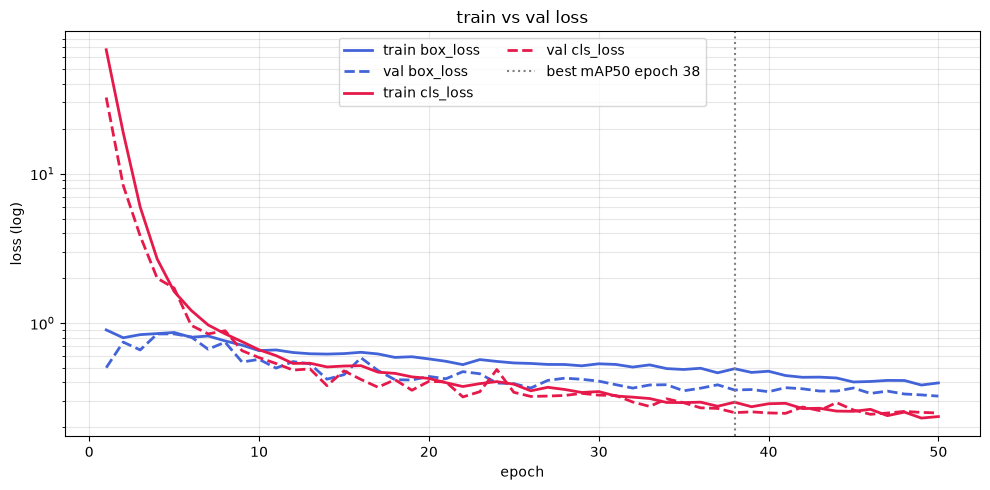

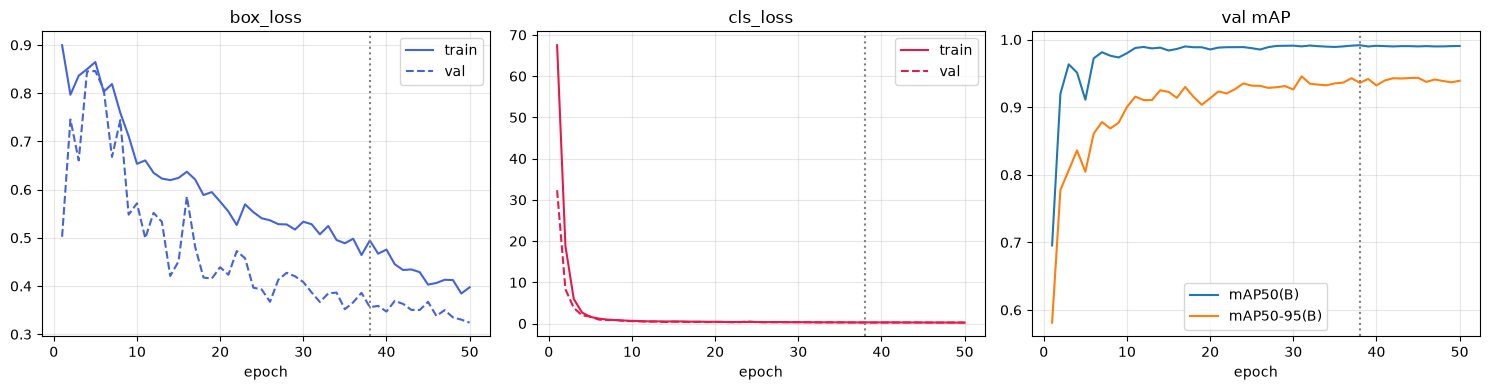

val loss 합 최저: epoch 50 (0.574) | 마지막 epoch train 0.634 / val 0.574
results.csv 최고 mAP50: epoch 38 = 0.9917 | best_map50.pt: epoch 38 = 0.9917


In [14]:
with open(SAVE_DIR / "results.csv", encoding="utf-8") as f:
    rows = [{k.strip(): v for k, v in r.items()} for r in csv.DictReader(f)]
cols = ["epoch", "train/box_loss", "train/cls_loss", "train/dfl_loss", "val/box_loss", "val/cls_loss", "val/dfl_loss",
        "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
cols = [c for c in cols if c in rows[0]]
print(" | ".join(c.replace("metrics/", "").replace("(B)", "") for c in cols))
for r in rows:
    print(" | ".join(f"{float(r[c]):.4f}" if c != "epoch" else f"{int(float(r[c])):>3d}" for c in cols))

ep = [int(float(r["epoch"])) for r in rows]
LOSSES = [k for k in ("box_loss", "cls_loss", "dfl_loss") if f"train/{k}" in rows[0] and f"val/{k}" in rows[0]]
LOSS_COLORS = {"box_loss": "#4363d8", "cls_loss": "#e6194b", "dfl_loss": "#3cb44b"}
best_ep = best_map50["epoch"]

# (1) train · val loss 한 그래프 — 같은 색 = 같은 loss, 실선 = train, 점선 = val
fig, ax = plt.subplots(figsize=(10, 5))
for k in LOSSES:
    ax.plot(ep, [float(r[f"train/{k}"]) for r in rows], color=LOSS_COLORS[k], ls="-", lw=2, label=f"train {k}")
    ax.plot(ep, [float(r[f"val/{k}"]) for r in rows], color=LOSS_COLORS[k], ls="--", lw=2, label=f"val {k}")
ax.axvline(best_ep, color="gray", ls=":", label=f"best mAP50 epoch {best_ep}")
ax.set_yscale("log")          # cls_loss 초반값이 커서 로그 축으로 같이 보이게
ax.set_xlabel("epoch"); ax.set_ylabel("loss (log)"); ax.set_title("train vs val loss")
ax.grid(alpha=0.3, which="both"); ax.legend(ncol=2)
fig.tight_layout(); fig.savefig(EXP_DIR / "loss_train_val.png", dpi=120); plt.show()

# (2) loss 종류별로 나눠서 train · val 비교 (선형 축) + val mAP
fig, axes = plt.subplots(1, len(LOSSES) + 1, figsize=(5 * (len(LOSSES) + 1), 4))
for a, k in zip(axes, LOSSES):
    a.plot(ep, [float(r[f"train/{k}"]) for r in rows], color=LOSS_COLORS[k], ls="-", label="train")
    a.plot(ep, [float(r[f"val/{k}"]) for r in rows], color=LOSS_COLORS[k], ls="--", label="val")
    a.set_title(k)
for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"):
    axes[-1].plot(ep, [float(r[c]) for r in rows], label=c.split("/")[1])
axes[-1].set_title("val mAP")
for a in axes:
    a.axvline(best_ep, color="gray", ls=":"); a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
fig.tight_layout(); fig.savefig(EXP_DIR / "curves.png", dpi=120); plt.show()

# 과적합 확인: val loss 합이 가장 낮았던 epoch vs best mAP50 epoch
tot = lambda r, s: sum(float(r[f"{s}/{k}"]) for k in LOSSES)
min_val = min(rows, key=lambda r: tot(r, "val"))
print(f"val loss 합 최저: epoch {int(float(min_val['epoch']))} ({tot(min_val, 'val'):.3f}) | "
      f"마지막 epoch train {tot(rows[-1], 'train'):.3f} / val {tot(rows[-1], 'val'):.3f}")

csv_best = max(rows, key=lambda r: float(r["metrics/mAP50(B)"]))
print(f"results.csv 최고 mAP50: epoch {int(float(csv_best['epoch']))} = {float(csv_best['metrics/mAP50(B)']):.4f} "
      f"| best_map50.pt: epoch {best_map50['epoch']} = {best_map50['mAP50']:.4f}")

## 9. 합성 데이터 최종 평가 — `best_map50.pt`로 val과 test 각각

test는 여기서 처음 써요. 결과는 `eval_val/`, `eval_test/`, 수치는 `metrics.json`.

In [15]:
best = YOLO(str(BEST_MAP50))
print("평가·추론 가중치:", BEST_MAP50, f"(epoch {best_map50['epoch']})")

def evaluate(data_yaml, split, tag):
    m = best.val(data=str(data_yaml), split=split, imgsz=TRAIN_CFG["imgsz"], batch=TRAIN_CFG["batch"],
                 device=TRAIN_CFG["device"], project=str(EXP_DIR), name=f"eval_{tag}", exist_ok=True, plots=True)
    per_class = {}
    for k, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        per_class[NAMES[int(c)]] = dict(P=round(float(p), 4), R=round(float(r), 4),
                                        mAP50=round(float(ap50), 4), mAP50_95=round(float(ap), 4))
    return dict(P=round(float(m.box.mp), 4), R=round(float(m.box.mr), 4),
                mAP50=round(float(m.box.map50), 4), mAP50_95=round(float(m.box.map), 4), per_class=per_class)

def print_metrics(metrics):
    print(f"\n{'split':10s} {'class':14s} {'P':>6s} {'R':>6s} {'mAP50':>7s} {'mAP50-95':>9s}")
    for split, mm in metrics.items():
        print(f"{split:10s} {'all':14s} {mm['P']:6.3f} {mm['R']:6.3f} {mm['mAP50']:7.3f} {mm['mAP50_95']:9.3f}")
        for name, pc in mm["per_class"].items():
            print(f"{'':10s} {name:14s} {pc['P']:6.3f} {pc['R']:6.3f} {pc['mAP50']:7.3f} {pc['mAP50_95']:9.3f}")

metrics = {f"sim_{s}": evaluate(DATA_YAML, s, f"sim_{s}") for s in ("val", "test")}
print_metrics(metrics)
save_json("metrics.json", metrics)

평가·추론 가중치: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/weights/best_map50.pt (epoch 38)
Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5028.1±1607.5 MB/s, size: 447.6 KB)
val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0_shape4/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 23.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.8it/s 1.8s0.1ss
                   all         50        132      0.985      0.956      0.992      0.947
              puck_cyl         30         41      0.984      0.927      0.989      0.935
              puck_box         45         66      0.984      0.943      0.99

## 9-R. 실물 광각 테스트 평가 — 합성과 따로 계산

- 4-R에서 만든 `data_real.yaml`(라벨 있는 실물 사진만)로 따로 평가해요. 결과는 `eval_real/`, 수치는 `metrics_real.json`.
- 합성 test 점수와 섞지 않아요. 두 점수 차이가 sim-to-real 차이예요.

In [16]:
metrics_real = None
if HAS_REAL_LABELS:
    metrics_real = {"real_test": evaluate(DATA_REAL_YAML, "test", "real")}
    print_metrics(metrics_real)
    save_json("metrics_real.json", metrics_real)
    gap = metrics["sim_test"]["mAP50"] - metrics_real["real_test"]["mAP50"]
    print(f"\nmAP50  합성 test {metrics['sim_test']['mAP50']:.3f}  vs  실물 {metrics_real['real_test']['mAP50']:.3f}  "
          f"(차이 {gap:+.3f})")
    for name in NAMES.values():
        if real_stats["per_class"][name] == 0:
            print(f"  · 실물 사진에 '{name}' 정답이 없어서 이 클래스 점수는 계산되지 않음")
else:
    print("실물 라벨이 없어 mAP 계산을 건너뜀 (4-R 참고)")

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 489.0±50.8 MB/s, size: 341.4 KB)
val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/real_test_set/labels/test... 49 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 1.8Kit/s 0.0s
val: New cache created: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/real_test_set/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.0it/s 1.8s0.1ss
                   all         49         94      0.311      0.136      0.177     0.0768
                    qr         16         23          0          0          0          0
              puck_cyl         38         68      0.93

## 10. 합성 test 예측 샘플 — `best_map50.pt`, confidence ≥ CONF(0.5, planning 기준)

Results saved to /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/train/results/experiment_1_20261023_110611/pred_sim_test


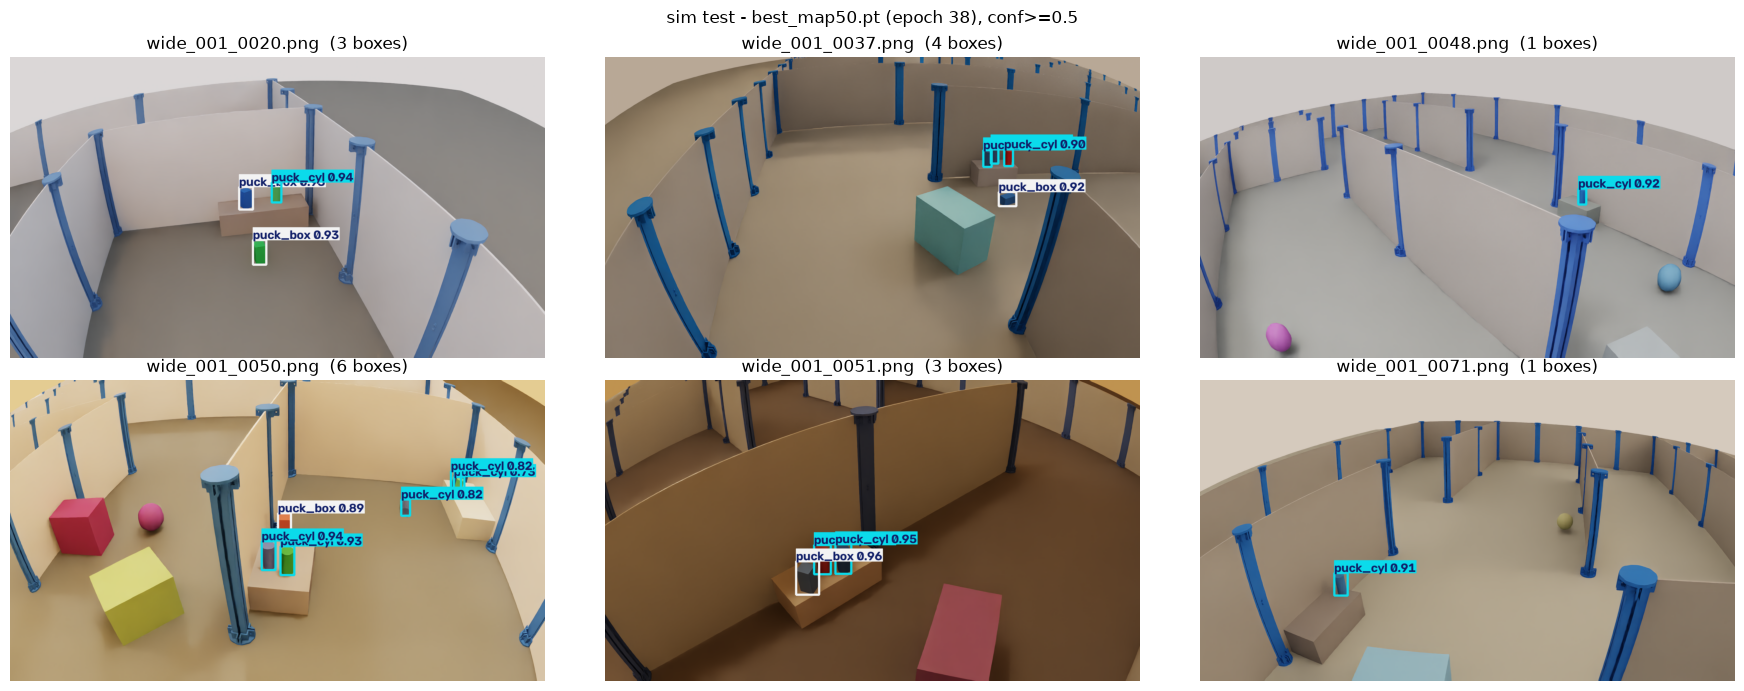

In [17]:
test_imgs = sorted((SPLIT_DATASET / "images" / "test").glob("*.png"))[:6]
preds = best.predict([str(p) for p in test_imgs], conf=CONF, imgsz=TRAIN_CFG["imgsz"], device=TRAIN_CFG["device"],
                     save=True, project=str(EXP_DIR), name="pred_sim_test", exist_ok=True, verbose=False)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for a, r in zip(axes.flat, preds):
    a.imshow(r.plot()[..., ::-1]); a.set_title(f"{Path(r.path).name}  ({len(r.boxes)} boxes)"); a.axis("off")
fig.suptitle(f"sim test - {BEST_MAP50.name} (epoch {best_map50['epoch']}), conf>={CONF}")
fig.tight_layout(); fig.savefig(EXP_DIR / "pred_sim_test_samples.png", dpi=80); plt.show()

## 10-R. 실물 광각 — 정답(왼쪽) vs 예측(오른쪽), 사진마다 따로

- 모든 실물 사진에 대해 `best_map50.pt`, confidence ≥ 0.5로 예측해요.
- 사진별로 정답 상자 수, 예측 상자 수, **놓친 정답(FN)**, **오탐(FP)**(IoU 0.5 기준, 같은 클래스끼리 매칭)을 세서 표와 `real_test_per_image.csv`로 저장해요.
- 나란히 놓은 이미지는 `real_test_vis/`에 한 장씩 저장돼요.

In [ ]:
def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x1 - x0) * max(0, y1 - y0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def gt_boxes(lbl, W, H):
    out = []
    if lbl.exists():
        for l in lbl.read_text().splitlines():
            if not l.strip(): continue
            c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
            out.append((c, [(cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H]))
    return out

real_rows = []
if HAS_REAL:
    VIS_DIR = EXP_DIR / "real_test_vis"; VIS_DIR.mkdir(exist_ok=True)
    real_preds = best.predict([str(p) for p in real_imgs], conf=CONF, imgsz=TRAIN_CFG["imgsz"],
                              device=TRAIN_CFG["device"], verbose=False)
    for p, r in zip(real_imgs, real_preds):
        H, W = r.orig_shape
        lbl = REAL_TEST_DIR / "labels" / (p.stem + ".txt")
        gts = gt_boxes(lbl, W, H)
        pds = [(int(b.cls), b.xyxy[0].tolist(), float(b.conf)) for b in r.boxes]
        used, tp = set(), 0
        for c, box, _ in sorted(pds, key=lambda x: -x[2]):
            cand = [(iou(box, g[1]), j) for j, g in enumerate(gts) if j not in used and g[0] == c]
            if cand and max(cand)[0] >= 0.5:
                used.add(max(cand)[1]); tp += 1
        labeled = lbl.exists()
        row = dict(image=p.name, labeled=labeled, gt=len(gts), pred=len(pds),
                   TP=tp if labeled else "", FN=len(gts) - tp if labeled else "", FP=len(pds) - tp if labeled else "",
                   pred_classes=" ".join(f"{NAMES[c]}:{s:.2f}" for c, _, s in pds))
        real_rows.append(row)

        gt_img = Image.open(p).convert("RGB"); d = ImageDraw.Draw(gt_img)
        for c, b in gts:
            d.rectangle(b, outline=COLORS[c % 4], width=3); d.text((b[0], max(0, b[1] - 12)), NAMES[c], fill=COLORS[c % 4])
        pred_img = Image.fromarray(r.plot()[..., ::-1])
        fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
        ax[0].imshow(gt_img); ax[0].set_title(f"GT ({len(gts)})" if labeled else "GT: no label file")
        ax[1].imshow(pred_img)
        ax[1].set_title(f"pred conf>={CONF} ({len(pds)})" + (f"  TP {row['TP']} · FN {row['FN']} · FP {row['FP']}" if labeled else ""))
        for a in ax: a.axis("off")
        fig.suptitle(p.name); fig.tight_layout(); fig.savefig(VIS_DIR / f"{p.stem}_gt_vs_pred.jpg", dpi=80); plt.show()

    with open(EXP_DIR / "real_test_per_image.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(real_rows[0])); w.writeheader(); w.writerows(real_rows)
    print(f"\n{'image':28s} {'GT':>3s} {'pred':>4s} {'TP':>3s} {'FN':>3s} {'FP':>3s}  예측")
    for r_ in real_rows:
        print(f"{r_['image'][:28]:28s} {r_['gt']:3d} {r_['pred']:4d} {str(r_['TP']):>3s} {str(r_['FN']):>3s} {str(r_['FP']):>3s}  {r_['pred_classes']}")
    lab = [r_ for r_ in real_rows if r_["labeled"]]
    if lab:
        TP, FN, FP = (sum(r_[k] for r_ in lab) for k in ("TP", "FN", "FP"))
        print(f"\n라벨 있는 {len(lab)}장 합계 (conf≥{CONF}, IoU≥0.5): TP {TP} · 놓친 정답 FN {FN} · 오탐 FP {FP} · "
              f"recall {TP / max(1, TP + FN):.3f} · precision {TP / max(1, TP + FP):.3f}")
        save_json("real_test_counts.json", dict(images=len(lab), TP=TP, FN=FN, FP=FP, conf=CONF, iou=0.5))
else:
    print("실물 사진이 없어 건너뜀")

## 11. 요약 — `summary.md`로 저장 (일지·Notion에 붙여 넣기용)

In [ ]:
lines = [f"# {RUN_ID}", "",
         f"- 시작 가중치: `{PRETRAINED.name}` (sha256 {sha[:12]}…), {weights_info['n_classes']}클래스 COCO 사전학습",
         f"- 가중치 이어받기: {transfer[-1] if transfer else '확인 필요'}",
         f"- 선택 가중치: `weights/{BEST_MAP50.name}` — val mAP50 최고 epoch {best_map50['epoch']} ({best_map50['mAP50']:.3f})",
         f"- 합성 데이터: `{SPLIT_DATASET.name}` (seed {SPLIT_SEED}) — "
         + ", ".join(f"{s} {stats[s]['images']}장/{stats[s]['boxes']}상자" for s in stats),
         f"- 실물 테스트: {real_stats['images']}장 (라벨 {real_stats['labeled']}장, 상자 {real_stats['boxes']}개)",
         f"- 설정: " + ", ".join(f"{k}={v}" for k, v in TRAIN_CFG.items()),
         f"- 환경: torch {env['torch']}, CUDA {env['cuda']}, {env['gpu']}, ultralytics {env['ultralytics']}, "
         f"git {env['git_branch']}@{env['git_commit']} (변경 {env['git_dirty_files']}개)",
         f"- 학습 시간: {train_min:.1f}분, epoch {len(rows)}", "",
         "| 데이터 | class | P | R | mAP50 | mAP50-95 |", "| --- | --- | --- | --- | --- | --- |"]
for split, mm in {**metrics, **(metrics_real or {})}.items():
    lines.append(f"| {split} | all | {mm['P']:.3f} | {mm['R']:.3f} | {mm['mAP50']:.3f} | {mm['mAP50_95']:.3f} |")
    for name, pc in mm["per_class"].items():
        lines.append(f"| {split} | {name} | {pc['P']:.3f} | {pc['R']:.3f} | {pc['mAP50']:.3f} | {pc['mAP50_95']:.3f} |")
if (EXP_DIR / "real_test_counts.json").exists():
    rc = json.loads((EXP_DIR / "real_test_counts.json").read_text(encoding="utf-8"))
    lines += ["", f"실물 사진별 집계 (conf≥{CONF}, IoU≥0.5): TP {rc['TP']} · FN {rc['FN']} · FP {rc['FP']} → `real_test_per_image.csv`, `real_test_vis/`"]
lines += ["", "주의: sim_val·sim_test는 합성 사진. 실물 성능은 real_test 행으로 판단."]
(EXP_DIR / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

print("\n실행 폴더 파일:")
for p in sorted(EXP_DIR.iterdir()):
    print(" ", p.name + ("/" if p.is_dir() else ""))
print(f"\n[{datetime.now():%F %T}] 끝")